# Phase 3A — Figure 1: Baseline Relative Band Power (PRE vs POST)

**Project:** EEG Control vs Experiment, PRE vs POST, Math and Reading.

This notebook creates the first Phase 3 visualization using **relative band power (%)**, the primary EEG metric established in Phase 1. It uses the existing ROI-aggregated dataset and performs no new inferential tests.


### Figure specification
- Condition: **Baseline only**
- X-axis: Session (PRE, POST)
- Y-axis: Relative band power (%)
- Lines: Control and Experiment groups
- Panels: Frequency bands × scalp ROIs (5 × 5)
- Error bars: 95% t-based confidence intervals around the participant mean
- Separate figures: Math and Reading


**Interpretation caution:** Relative power is compositional. A change in one band’s percentage necessarily affects the proportion available to the other bands; these plots do not independently represent absolute neural activity.

In [1]:
# Imports
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import t


In [2]:
# Robustly locate the input CSV on a Mac or in a hosted notebook environment.
INPUT_FILENAME = "eeg_roi_power_long.csv"
search_roots = [
    Path.cwd(),
    Path.home() / "Term Project",
    Path.home(),
    Path("/mnt/data"),
]

input_path = None
seen = set()
for root in search_roots:
    if not root.exists():
        continue
    try:
        for candidate in root.rglob(INPUT_FILENAME):
            if candidate in seen:
                continue
            seen.add(candidate)
            input_path = candidate
            break
    except (PermissionError, OSError):
        continue
    if input_path is not None:
        break

if input_path is None:
    raise FileNotFoundError(
        f"Could not find {INPUT_FILENAME}. Place it in your Term Project folder " 
        "or update INPUT_FILENAME / search_roots."
    )

PROJECT_ROOT = input_path.parent
OUTPUT_DIR = PROJECT_ROOT / "phase3_figures" / "figure1_baseline_relative_power"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Input CSV: {input_path}")
print(f"Figures will save to: {OUTPUT_DIR}")


Input CSV: /Users/ananyosen/Documents/Term Project/analysis/eeg_roi_step2_outputs/eeg_roi_power_long.csv
Figures will save to: /Users/ananyosen/Documents/Term Project/analysis/eeg_roi_step2_outputs/phase3_figures/figure1_baseline_relative_power


In [3]:
# Load and inspect the ROI-level dataset
raw = pd.read_csv(input_path)
required_columns = {
    "subject_id", "group", "task", "session", "condition", "band", "roi", "relative_power_roi"
}
missing_columns = required_columns - set(raw.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

raw["relative_power_roi"] = pd.to_numeric(raw["relative_power_roi"], errors="coerce")
print("Rows:", len(raw))
print("Participants:", raw["subject_id"].nunique())
print("Groups:", sorted(raw["group"].dropna().unique()))
print("Tasks:", sorted(raw["task"].dropna().unique()))
print("Sessions:", sorted(raw["session"].dropna().unique()))
print("Bands:", sorted(raw["band"].dropna().unique()))
print("ROIs:", sorted(raw["roi"].dropna().unique()))


Rows: 8000
Participants: 63
Groups: ['Control', 'Experiment']
Tasks: ['Math', 'Reading']
Sessions: ['POST', 'PRE']
Bands: ['alpha', 'beta', 'delta', 'gamma', 'theta']
ROIs: ['Central', 'Frontal', 'Occipital', 'Parietal', 'Temporal']


In [4]:
# Select Baseline condition and prepare participant-level values
baseline = raw[raw["condition"].astype(str).str.strip().str.lower() == "baseline"].copy()
# Expected unit: one participant × task × session × band × ROI for Baseline.
key = ["subject_id", "group", "task", "session", "band", "roi"]
duplicates = baseline.duplicated(key, keep=False)
print("Baseline rows:", len(baseline))
print("Duplicate participant-level keys:", int(duplicates.sum()))
print("Missing relative-power values:", int(baseline["relative_power_roi"].isna().sum()))
if duplicates.any():
    raise ValueError("Duplicate baseline participant-level rows found. Resolve before plotting.")

# Validate band percentages sum to 100 within each participant/session/task/ROI.
sum_key = ["subject_id", "group", "task", "session", "roi"]
band_sum = baseline.groupby(sum_key, dropna=False)["relative_power_roi"].sum()
print("Band-sum groups:", len(band_sum))
print("Groups outside 100 ± 0.01 percentage points:", int((~np.isclose(band_sum, 100, atol=0.01)).sum()))


Baseline rows: 3150
Duplicate participant-level keys: 0
Missing relative-power values: 0
Band-sum groups: 630
Groups outside 100 ± 0.01 percentage points: 0


In [5]:
# Order categories consistently across figures
session_order = ["PRE", "POST"]
group_order = ["Control", "Experiment"]
band_order = ["delta", "theta", "alpha", "beta", "gamma"]
roi_order = ["Frontal", "Central", "Temporal", "Parietal", "Occipital"]

# Normalize capitalization only for plotting labels (values remain unchanged).
plot_data = baseline.copy()
plot_data["session"] = plot_data["session"].astype(str).str.upper().str.strip()
plot_data["band_plot"] = plot_data["band"].astype(str).str.lower().str.strip()
plot_data["roi_plot"] = plot_data["roi"].astype(str).str.title().str.strip()
plot_data["group"] = plot_data["group"].astype(str).str.title().str.strip()
plot_data = plot_data[plot_data["session"].isin(session_order)]
plot_data = plot_data[plot_data["band_plot"].isin(band_order)]
plot_data = plot_data[plot_data["roi_plot"].isin(roi_order)]


In [6]:
# Compute mean and 95% t-based CI for plotting
summary = (
    plot_data.groupby(["task", "roi_plot", "band_plot", "group", "session"], observed=True)["relative_power_roi"]
    .agg(mean="mean", sd="std", n="count")
    .reset_index()
)
summary["se"] = summary["sd"] / np.sqrt(summary["n"])
summary["tcrit"] = summary.apply(lambda r: t.ppf(0.975, r["n"] - 1) if r["n"] > 1 else np.nan, axis=1)
summary["ci95"] = summary["se"] * summary["tcrit"]
summary["lower"] = summary["mean"] - summary["ci95"]
summary["upper"] = summary["mean"] + summary["ci95"]
summary.to_csv(OUTPUT_DIR / "figure1_baseline_relative_power_summary.csv", index=False)
summary.head()


,task,roi_plot,band_plot,group,session,mean,sd,n,se,tcrit,ci95,lower,upper
0,Math,Central,alpha,Control,POST,5.835139,3.727658,15,0.962477,2.144787,2.064308,3.770831,7.899447
1,Math,Central,alpha,Control,PRE,7.053986,5.442461,15,1.405237,2.144787,3.013935,4.040051,10.067920
2,Math,Central,alpha,Experiment,POST,6.261704,5.456282,19,1.251757,2.100922,2.629844,3.631860,8.891548
3,Math,Central,alpha,Experiment,PRE,5.892393,2.939146,19,0.674286,2.100922,1.416623,4.475770,7.309016
4,Math,Central,beta,Control,POST,8.654144,9.416605,15,2.431357,2.144787,5.214742,3.439402,13.868886


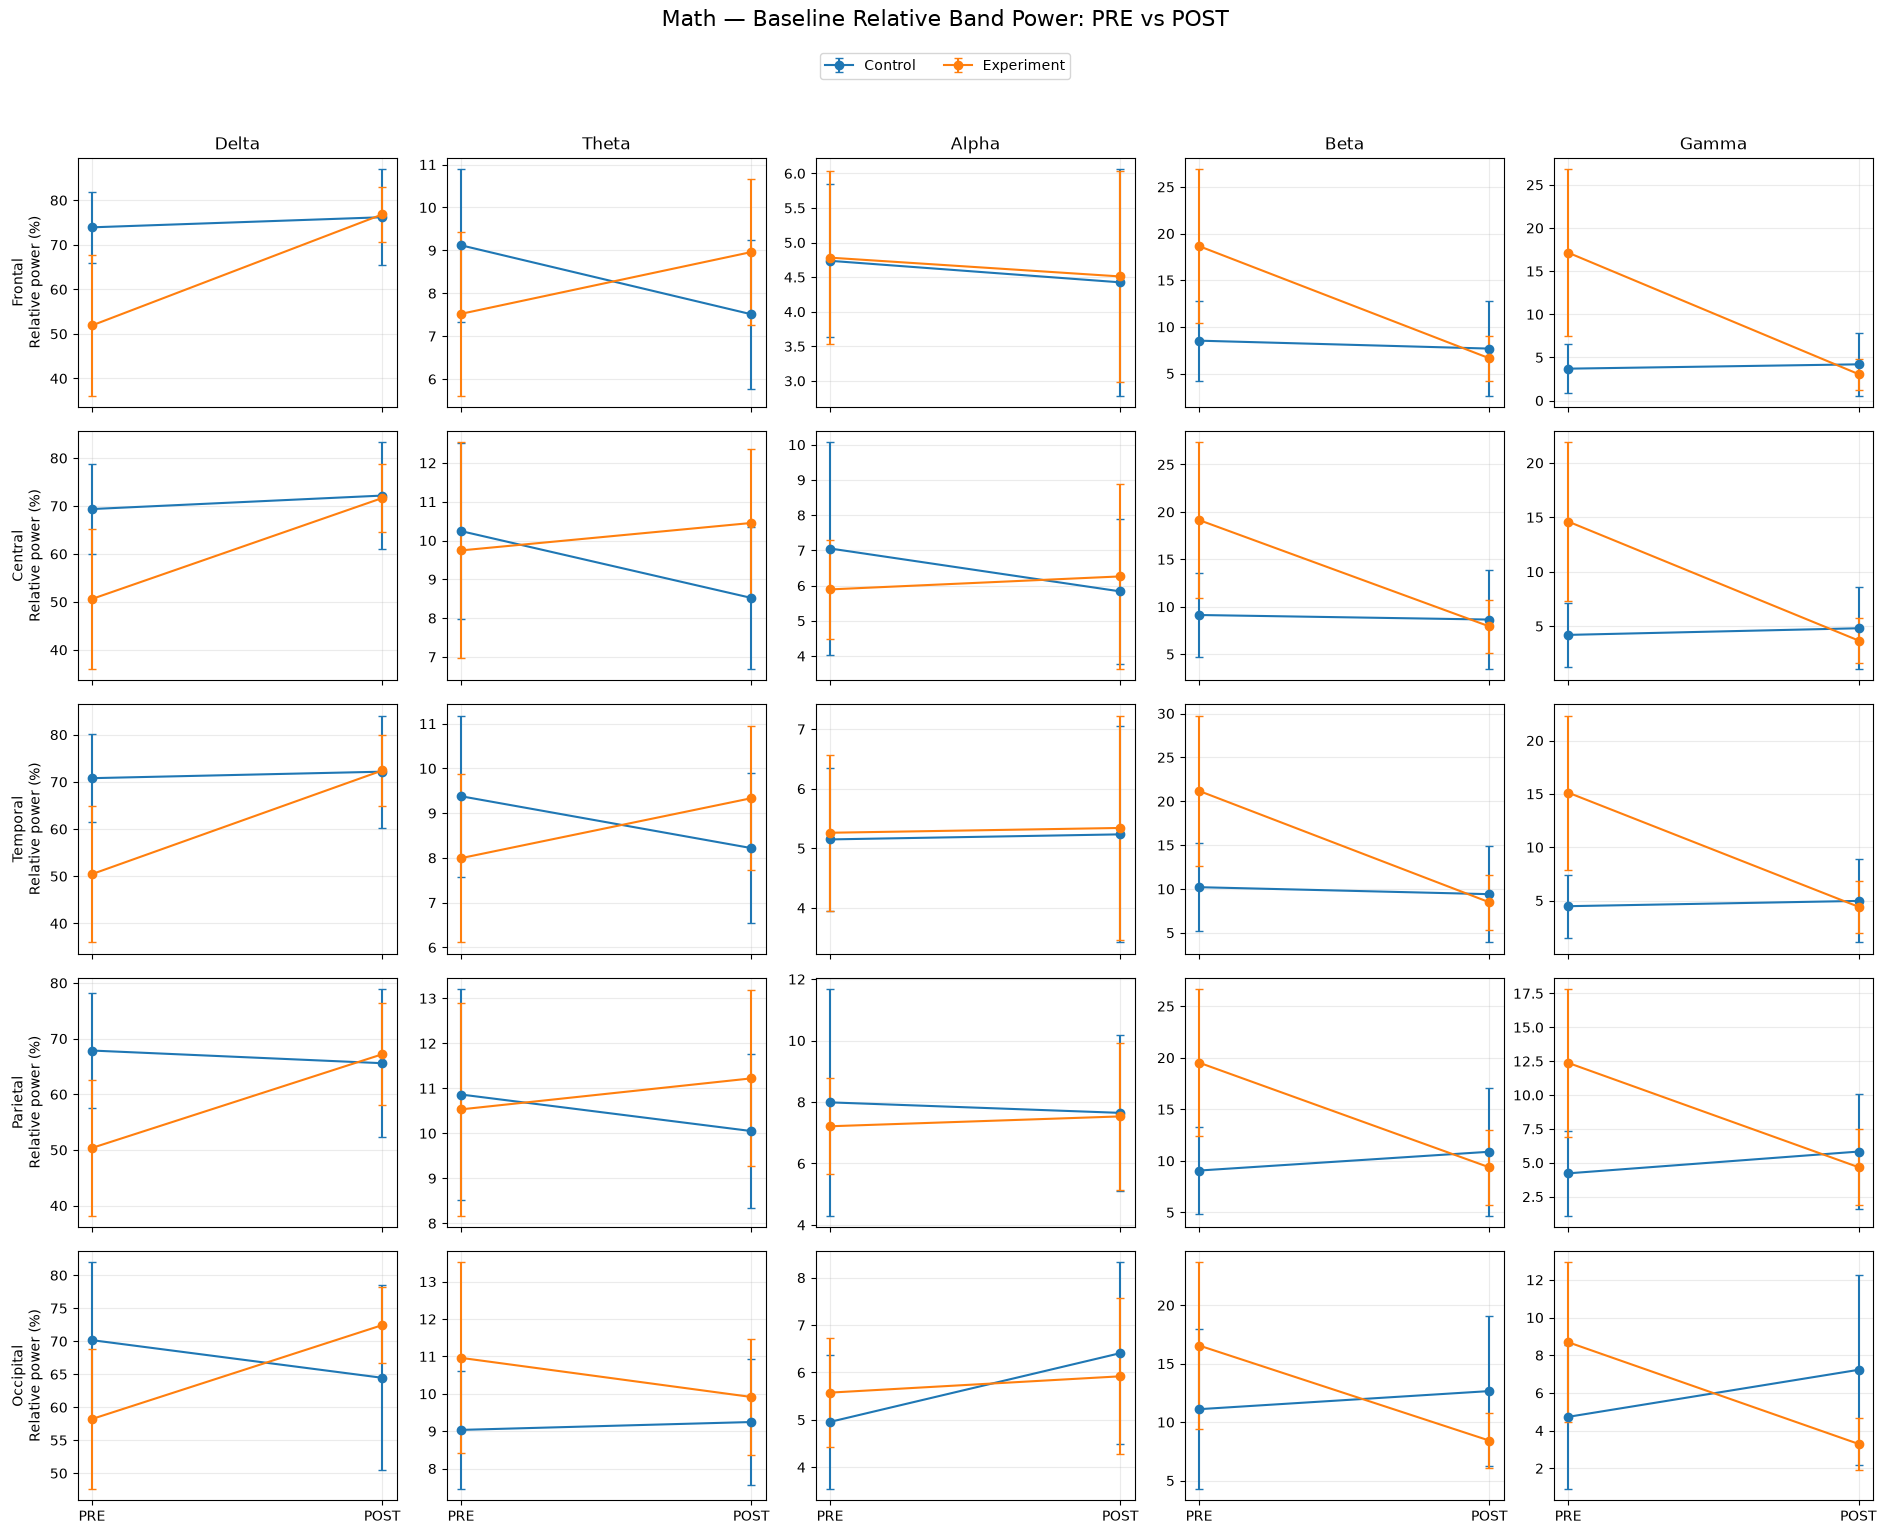

Saved: /Users/ananyosen/Documents/Term Project/analysis/eeg_roi_step2_outputs/phase3_figures/figure1_baseline_relative_power/figure1_math_baseline_relative_power_pre_post.png


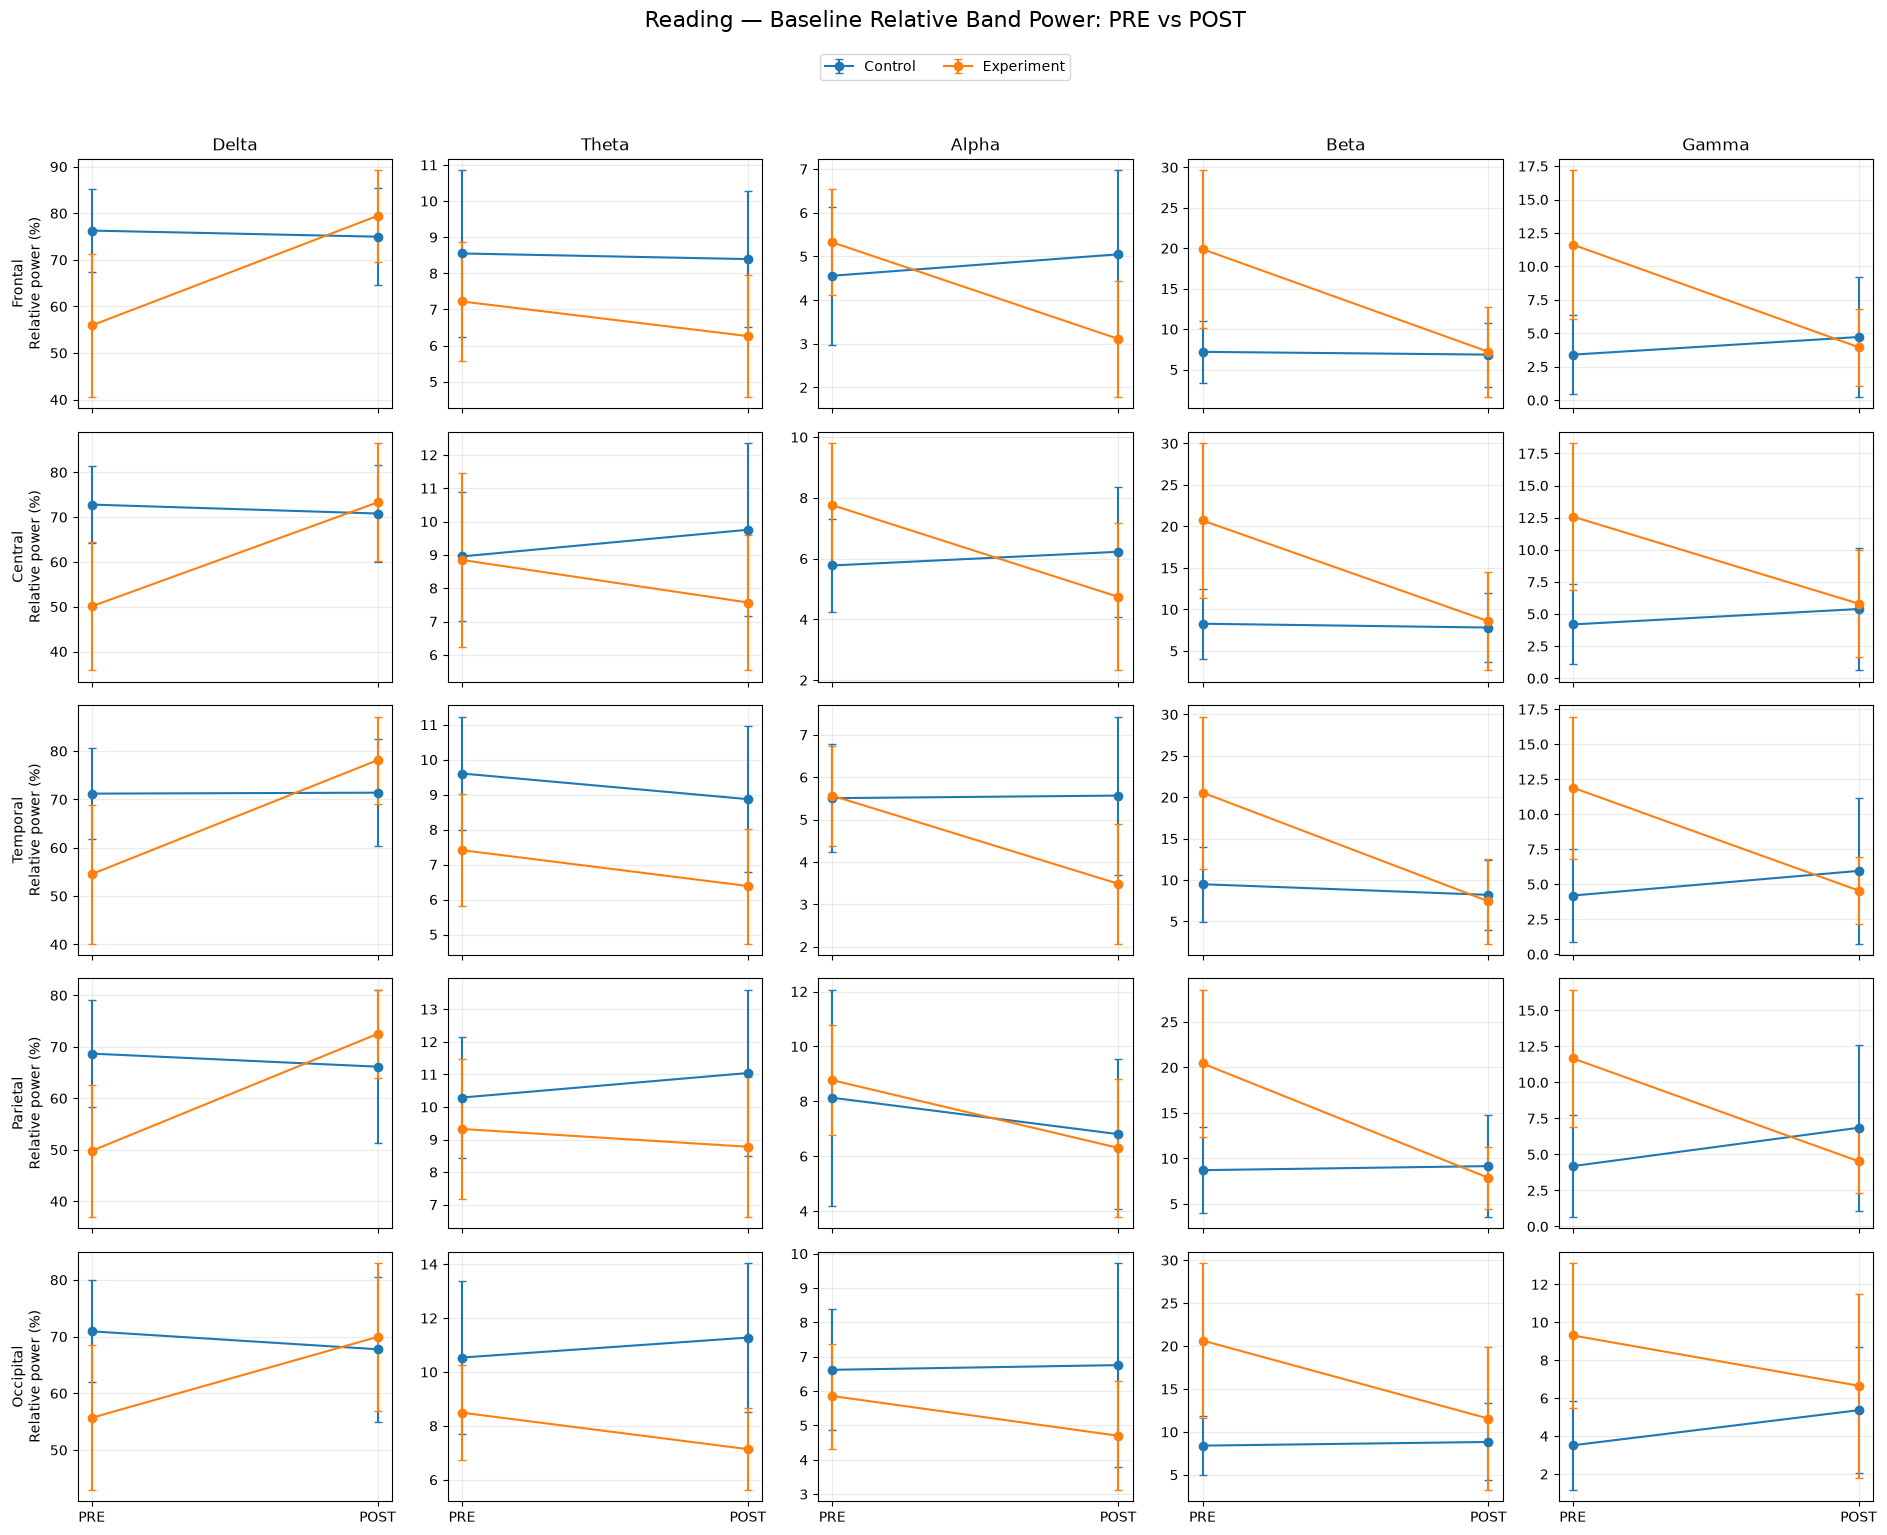

Saved: /Users/ananyosen/Documents/Term Project/analysis/eeg_roi_step2_outputs/phase3_figures/figure1_baseline_relative_power/figure1_reading_baseline_relative_power_pre_post.png


In [7]:
# Figure generation: one 5 × 5 panel figure per task
# Each panel is one ROI × frequency band. Lines connect PRE and POST group means.
for task_name in sorted(summary["task"].dropna().unique()):
    task_summary = summary[summary["task"] == task_name]
    fig, axes = plt.subplots(5, 5, figsize=(19, 15), sharex=True)
    for i, roi_name in enumerate(roi_order):
        for j, band_name in enumerate(band_order):
            ax = axes[i, j]
            panel = task_summary[(task_summary["roi_plot"] == roi_name) & (task_summary["band_plot"] == band_name)]
            for group_name in group_order:
                line = panel[panel["group"] == group_name].set_index("session").reindex(session_order)
                if line["mean"].notna().sum() == 0:
                    continue
                x = np.arange(len(session_order))
                y = line["mean"].to_numpy(dtype=float)
                ci = line["ci95"].to_numpy(dtype=float)
                ax.errorbar(x, y, yerr=ci, marker="o", capsize=3, label=group_name)
            if i == 0:
                ax.set_title(band_name.capitalize())
            if j == 0:
                ax.set_ylabel(f"{roi_name}\nRelative power (%)")
            ax.set_xticks([0, 1], session_order)
            ax.grid(True, alpha=0.25)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 0.995))
    fig.suptitle(f"{task_name} — Baseline Relative Band Power: PRE vs POST", y=1.02, fontsize=16)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    output_file = OUTPUT_DIR / f"figure1_{task_name.lower()}_baseline_relative_power_pre_post.png"
    fig.savefig(output_file, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved:", output_file)


In [8]:
# Final output checklist
print("Phase 3A Figure 1 complete")
print("Output folder:", OUTPUT_DIR)
print("Summary CSV:", OUTPUT_DIR / "figure1_baseline_relative_power_summary.csv")
print("Expected figures:")
for task_name in sorted(summary["task"].dropna().unique()):
    print(f" - figure1_{task_name.lower()}_baseline_relative_power_pre_post.png")


Phase 3A Figure 1 complete
Output folder: /Users/ananyosen/Documents/Term Project/analysis/eeg_roi_step2_outputs/phase3_figures/figure1_baseline_relative_power
Summary CSV: /Users/ananyosen/Documents/Term Project/analysis/eeg_roi_step2_outputs/phase3_figures/figure1_baseline_relative_power/figure1_baseline_relative_power_summary.csv
Expected figures:
 - figure1_math_baseline_relative_power_pre_post.png
 - figure1_reading_baseline_relative_power_pre_post.png
